# LangSmith 基本使用


## 为什么不能只看模型的最终回答？

模型回答错了，可能是提示词没传对、检索资料不相关、工具执行失败，也可能是模型自身的判断问题。只打印最终回答，无法区分这些原因；一个复杂 Agent 的耗时也不能只靠最后一个模型响应解释。

**LangSmith** 是面向大模型应用的追踪、调试、监控和评估平台。本篇根据课程第 03 章的 9 页课件整理，先把一次模型调用接入追踪，再看懂项目、调用记录和监控指标。

本篇沿用 7.2 的分节方式：先解释问题，再给步骤、代码和验证方法。所有代码只作阅读示例，放在 Markdown 代码块中。


## 先分清：Project、Trace 与 Run

这三个名称决定了去哪里查问题：

| 概念 | 含义 | 例子 |
| --- | --- | --- |
| Project（项目） | 归集一类运行记录的容器 | `langchain03-demo`，由 `LANGSMITH_PROJECT` 指定 |
| Trace（调用链） | 一次请求从入口到结束的完整执行树 | 一次“查订单并解释退款规则”的请求 |
| Run（运行记录） | 调用链中的一个具体操作 | 检索、模型调用或工具执行 |

一个 Trace 可以包含根 Run 和多个子 Run。简单程序只调用一次模型时，看到的树可能只有一个模型 Run；Agent 或 RAG 经过多个组件时，才能展开对应步骤。

~~~text
Project：客服测试
└─ Trace：一次用户请求
   └─ 根 Run：客服流程
      ├─ 子 Run：检索退款规则
      ├─ 子 Run：模型决定查询订单
      ├─ 子 Run：订单工具
      └─ 子 Run：模型生成最终回答
~~~

Project 是归档范围，不是会话记忆；同一项目里的请求不会因此自动共享消息历史。


## LangSmith 的核心功能

先用 Tracing 定位一次请求，再用 Monitoring 看一段时间的运行状况；修改提示词或模型后，用数据集和评估器判断是否变好。

| 功能 | 解决的问题 | 典型用法 |
| --- | --- | --- |
| Tracing（追踪） | 这次请求到底经过了哪些步骤？ | 查实际 Prompt、模型输出、工具参数、错误和耗时 |
| Monitoring（监控） | 系统整体是否稳定、成本是否上升？ | 看请求量、错误率、延迟、Token 和成本趋势 |
| Datasets & Experiments（数据集与实验） | 新旧版本在相同问题上谁更好？ | 固定测试集，对比模型或提示词版本 |
| Evaluators（评估器） | 怎样给结果打分？ | 规则校验、人工评分或模型评判 |
| Annotation Queues（标注队列） | 哪些结果需要业务专家复核？ | 人工纠错、打标签，形成评测样本 |

**Tracing 记录过程，Evaluation 评估质量。** 一次调用没有报错，不代表回答正确；延迟低，也不代表任务完成得好。


## 提示词、调试与部署工具

课件还介绍了以下入口，初学阶段先认识职责即可：

| 入口 | 用途 |
| --- | --- |
| Prompts | 管理提示词版本、共享与复用 |
| Playground | 在网页中尝试模型和提示词，快速比较输出 |
| Studio | 可视化调试 LangGraph 的节点执行和状态流转 |
| Context Hub | 课件中的公共上下文与配置管理入口 |
| Deployments | 管理应用或 Agent 的部署与服务端点 |
| Sandboxes | 在隔离环境中试运行代码或 Agent |

这些是课程时期的产品入口，具体功能和可用权限以当前界面为准。Playground 调用模型仍需配置对应模型服务；拥有 LangSmith API Key 不等于拥有模型服务的密钥。

本章实际操作集中在 Tracing 与 Monitoring，数据集、评估、部署等这里只说明用途。


## 第一步：登录并创建 LangSmith API Key

访问 [LangSmith 控制台](https://smith.langchain.com/)，注册或登录，确认当前组织和工作区。

在课程界面中，创建路径是：

1. 打开 **Settings**。
2. 进入 **API Keys**，点击新增 Key。
3. 设置名称、类型、工作区及到期时间。
4. 创建后立即复制并保存密钥。

密钥只在创建时完整显示；忘记后通常需要重新创建。个人学习可使用个人 Key，自动化部署则按组织要求选用服务 Key。若密钥泄露或不再使用，在设置中撤销它。

**两种 Key 分工不同**：LangSmith Key 用于上传和读取追踪数据，DeepSeek 等模型 Key 用于调用模型，不能互换。

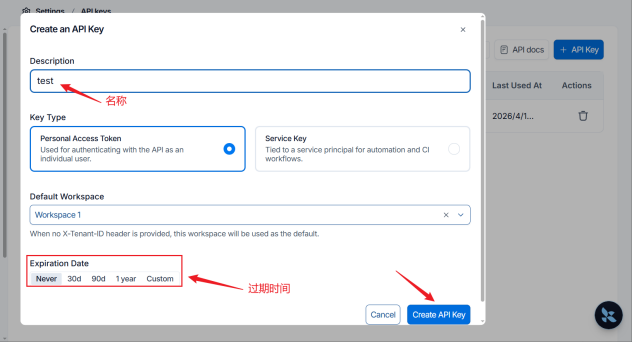

课程图示：创建 API Key 时选择类型、工作区和到期时间。


## 第二步：在 `.env` 中启用追踪

保留上一章的模型配置，新增四个 LangSmith 变量：

~~~dotenv
# 模型服务配置
DEEPSEEK_API_KEY=你的模型服务密钥
DEEPSEEK_BASE_URL=https://api.deepseek.com

# LangSmith 追踪配置
LANGSMITH_TRACING=true
LANGSMITH_ENDPOINT=https://api.smith.langchain.com
LANGSMITH_API_KEY=你的LangSmith密钥
LANGSMITH_PROJECT=langchain03-demo
~~~

| 变量 | 作用 |
| --- | --- |
| `LANGSMITH_TRACING` | 启用追踪；可用 `false` 关闭 |
| `LANGSMITH_ENDPOINT` | SDK 上传数据的 API 服务地址，区别于网页登录地址 |
| `LANGSMITH_API_KEY` | LangSmith 认证密钥 |
| `LANGSMITH_PROJECT` | 运行记录归入的项目名 |

课件使用上面的 API 地址；如果工作区位于其他服务区域，应使用该区域提供的地址。

`.env` 加入 `.gitignore`，可以提交只含变量名和占位符的 `.env.example`。启用云端追踪后，接入的调用可能会上传输入、输出和元数据；业务数据需要按项目要求进行脱敏。


## 第三步：运行一次带追踪的模型调用

环境变量不会因为写进 `.env` 就自动生效。先通过 `load_dotenv()` 加载，再创建模型和调用它。

下面使用课件版本的 `ChatDeepSeek` 专用类；模型名需要替换成账户当前可用的名称。

~~~python
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    api_key=os.environ["DEEPSEEK_API_KEY"],
    api_base=os.environ["DEEPSEEK_BASE_URL"],
)

response = model.invoke("你好，请用一句话回答")
print(response.content)
~~~

`override=True` 让 `.env` 覆盖进程中已有的同名变量。课程使用这项设置来保证演示配置一致；线上由部署环境注入配置时，应明确是否允许被文件覆盖。

对已接入 LangChain 回调的模型调用，启用追踪后一般不必额外写“上传日志”代码。普通 Python 函数或外部操作不会因为设置了变量就全部自动变成子 Run，仍需对应的追踪集成。


## 同样可以追踪兼容接口

课件的第二种写法使用 `init_chat_model` 加载 OpenAI 协议适配器，再连接实际模型平台：

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
)

response = model.invoke("你好，请用一句话回答")
print(response.content)
~~~

这段代码另需在 `.env` 中提供 `CLOSEAI_API_KEY` 和 `CLOSEAI_BASE_URL`，仍然复用前面的四个 LangSmith 变量。这里的 `openai` 指接口适配器；追踪中显示的类名可能是 `ChatOpenAI`，实际模型由请求地址和模型名决定。


## 第四步：用 `config` 标记本次运行

项目中出现几十条记录后，单靠默认模型类名很难查找。可以在调用时传入名称、标签和业务元数据：

~~~python
response = model.invoke(
    "1 + 2 = ？",
    config={
        "run_name": "math-smoke-test",
        "tags": ["chapter03", "development"],
        "metadata": {
            "user_id": "demo-user",
            "session_id": "demo-session",
        },
    },
)
print(response.content)
~~~

| 配置 | 帮助什么 |
| --- | --- |
| `run_name` | 用业务名称识别一次运行 |
| `tags` | 筛选环境、实验组或任务类型 |
| `metadata` | 保存结构化业务信息，便于定位记录 |

`metadata` 里的用户和会话字段只是记录信息。它们不会自动保存消息，也不会自动让下一轮调用恢复对话。

使用场景一：给客服与摘要任务打不同标签，比较耗时。使用场景二：记录提示词版本，查出修改后哪一批回答质量下降。


## 动态调整模型参数需要先声明可配置字段

课件的第三个例子除了追踪标签，还通过 `configurable` 改变模型参数。这属于模型调用能力，不是 LangSmith 自己改变模型。

只有支持动态配置的对象才会读取这些值。下面在 `init_chat_model` 中先声明允许调整的字段，再在单次调用中覆盖它们：

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=os.environ["DEEPSEEK_API_KEY"],
    api_base=os.environ["DEEPSEEK_BASE_URL"],
    temperature=0.2,
    max_tokens=500,
    configurable_fields=("temperature", "max_tokens"),
)

response = model.invoke(
    "1 + 2 = ？",
    config={
        "run_name": "math-config-test",
        "tags": ["chapter03"],
        "configurable": {
            "temperature": 0.7,
            "max_tokens": 1000,
        },
    },
)
print(response.content)
~~~

> 给普通模型对象随便传入 `configurable`，并不保证参数被覆盖。若还要动态切换供应商，需声明相应字段，并同时核对新供应商的密钥、地址和依赖包；不能只改 `model_provider`。


## 第五步：在 Tracing 中找到项目

运行模型代码后，进入控制台的 **Tracing**，找到名为 `langchain03-demo` 的项目。它应与 `.env` 中的 `LANGSMITH_PROJECT` 一致；课件截图使用的是讲师自己的项目名。

点击项目，进入运行列表，选择相同时间和运行名称的那条记录。检查时间范围、工作区和筛选条件，避免把“列表暂时没显示”误认为没有上传。

**接入成功的验证**：模型返回了结果，同时项目中出现对应 Run，并能查看输入、输出和运行状态。只看到终端回复，只能证明模型调用成功。

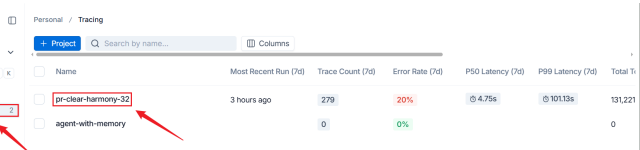

课程图示：在 Tracing 项目列表中寻找配置的项目名称。


## 怎样阅读一次调用记录？

排查时按“输入 → 执行树 → 输出 → 错误 → 耗时和用量”阅读：

| 查看内容 | 要判断什么 |
| --- | --- |
| Input / Prompt | 真正发送了哪些消息？系统提示和历史是否齐全？ |
| Output | 回答或工具调用是否符合预期？ |
| Run Tree | 是哪一步先出现问题？模型、检索还是工具？ |
| Error | 是认证、请求参数、网络，还是业务代码错误？ |
| Latency | 请求慢在哪个步骤？是否包含重试或多次模型调用？ |
| Tokens | 输入历史是否过长，输出是否超出任务需要？ |

例如：回答忘记了用户姓名，先看实际输入是否包含历史；回答引用错误文档，先查检索子 Run。不要只通过最终文本猜测原因。

Token 或成本字段是否完整，取决于集成和服务商返回的数据。没有显示不代表消耗为零。

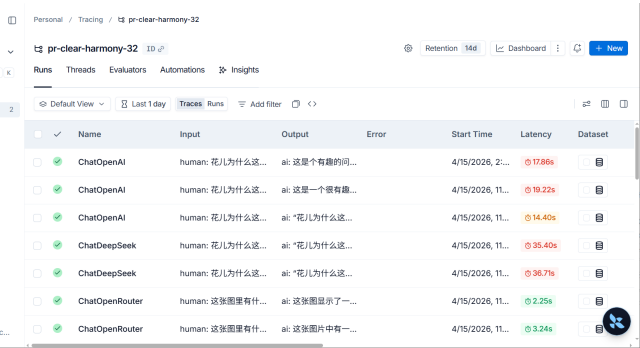

课程图示：运行列表展示输入、输出、状态与延迟，点击记录查看详情。


## 第六步：用 Monitoring 看整体趋势

Tracing 适合定位一次请求，Monitoring 适合判断一段时间内系统有没有变差。进入 **Monitoring**，选择同一个项目和时间范围，再查看 Traces、LLM Calls、Cost & Tokens、Tools 或反馈评分等分组。

| 指标 | 含义 | 变化时先查什么 |
| --- | --- | --- |
| Trace / LLM Call Count | 请求数与模型调用数 | 是否流量增加，或每次请求开始调用更多模型？ |
| Error Rate | 失败记录占比 | 是否认证失效、参数变化、服务故障或限流？ |
| Latency | 请求或模型调用的耗时 | 哪个步骤变慢？是否新增工具或重试？ |
| Token Usage | 输入和输出的 Token 消耗 | 历史消息、检索资料、提示词或回答是否变长？ |
| Cost | 按模型价格和用量估算的成本 | 价格映射是否正确，供应商账单口径是否一致？ |
| Feedback Scores | 人工或自动评估结果 | 是否与最近模型、Prompt 或检索改动有关？ |

QPS 表示每秒请求数；只看一段时间内的总调用数还不能直接当作 QPS。对比时应统一时间窗口、筛选条件和任务类型。

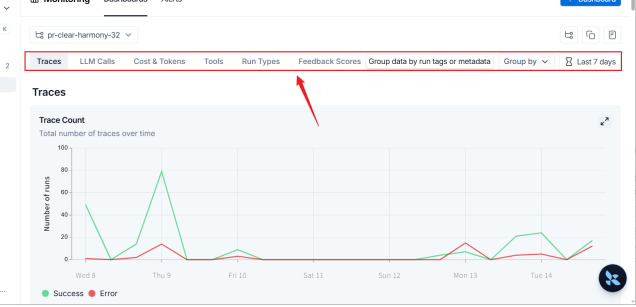

课程图示：按项目与时间范围切换监控指标。


## P50 与 P99：普通用户和最慢的一批用户

平均耗时可能掩盖慢请求。**P50** 是延迟中位数，约一半请求比它快；**P99** 表示约 99% 请求不超过的延迟，体现最慢的一小批请求的等待情况。

如果 P50 基本不变、P99 突然升高，多数请求可能正常，但部分请求遇到排队、重试、长输出或复杂工具流程。先从慢请求进入 Trace 查原因。

如果模型调用数增加但请求数不变，可能是每次任务多走了几轮模型与工具循环；此时成本上升不一定由输入 Token 变长引起。

监控报表帮助找到异常范围，具体原因仍需要回到调用树。

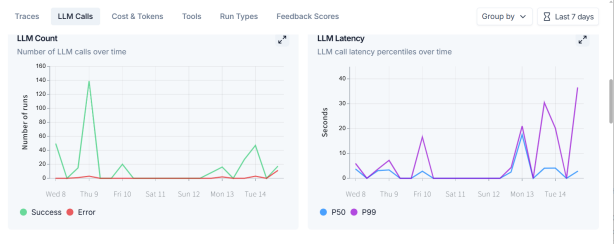

课程图示：模型调用数量与 P50/P99 延迟趋势。


## 没看到追踪记录时，按什么顺序排查？

| 现象 | 核对事项 |
| --- | --- |
| 模型回答正常，项目为空 | `.env` 是否加载，`LANGSMITH_TRACING` 是否为 `true`？ |
| 数据出现在其他项目 | 实际进程中的 `LANGSMITH_PROJECT` 是否被旧变量覆盖？ |
| 上传失败或认证报错 | LangSmith Key 是否有效，API 地址是否对应正确服务区域？ |
| 看不到刚才的运行 | 是否选错组织、工作区、时间范围或筛选标签？ |
| 只有模型 Run，没有业务流程 | 自定义函数是否接入追踪，而非只有模型调用被记录？ |
| Token / 成本缺失 | 模型服务是否返回用量，集成是否提供相应映射？ |

课件依赖已经在 `requirements.txt` 中统一声明。遇到包或 SDK 报错时，先核对依赖版本与初始化参数，再排查服务连接；不必重复安装所有库。


## 复习：从能运行到能解释为什么

本章的完整路线是：

~~~text
注册/登录 → 创建 LangSmith Key → 配置 .env
         → 加载环境变量 → 调用模型并添加 config
         → Tracing 查记录 → Monitoring 看趋势
~~~

接入追踪后，应能回答四个问题：实际传给模型的是什么、任务经过了哪些步骤、哪里失败或变慢、消耗了多少 Token。

当要比较模型或提示词版本时，下一步是固定测试集并运行实验。规则评估适合字段和格式检查；模型评判适合相关性等开放问题，但要用人工样本校准，不能把模型评分当成绝对真值。

**面试提示**：Tracing 解决可观测性，Evaluation 解决质量比较，记忆组件解决上下文保存。记录 `session_id` 或查看 Trace，都不等于应用已经具备多轮记忆。

资料来源：课程压缩包 `01-课件.rar` 中的《尚硅谷-03-LangSmith的使用.pdf》（第 03 章，共 9 页）。截图为课件中的界面示例，不表示在本机实际登录、调用或上传过数据。
